# House Prices Prediction - Version 1
 Ridge regression baseline

Steps: explore the data, handle missing values, create six features, compare Ridge with and without them, and save predictions.
The focus is on explaining our decisions and recording what helps.


## 1. Import libraries



In [45]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

sns.set_theme(style="whitegrid")


## 2. Load the data

Keep the text "None" as a category. In columns such as MasVnrType, it means that the feature is absent.
Only blank cells and "NA" are read as missing values.


In [46]:
data_dir = Path("Dataset")
if not data_dir.exists():
    data_dir = Path("Proj/Dataset")
if not data_dir.exists():
    data_dir = Path("/kaggle/input/house-prices-advanced-regression-techniques")

train = pd.read_csv(data_dir / "train.csv", keep_default_na=False, na_values=["", "NA"])
test = pd.read_csv(data_dir / "test.csv", keep_default_na=False, na_values=["", "NA"])

print("Train:", train.shape)
print("Test:", test.shape)
train.head()


Train: (1460, 81)
Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


train.info()
print("Duplicate train IDs:", train["Id"].duplicated().sum())
print("Duplicate test IDs:", test["Id"].duplicated().sum())
print("Missing target values:", train["SalePrice"].isna().sum())

## 3. Explore the data

### SalePrice distribution

The competition evaluates RMSE between log prices. We use the natural log of SalePrice as the target and exp() to convert predictions back to prices.
[Official metric](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview/description).


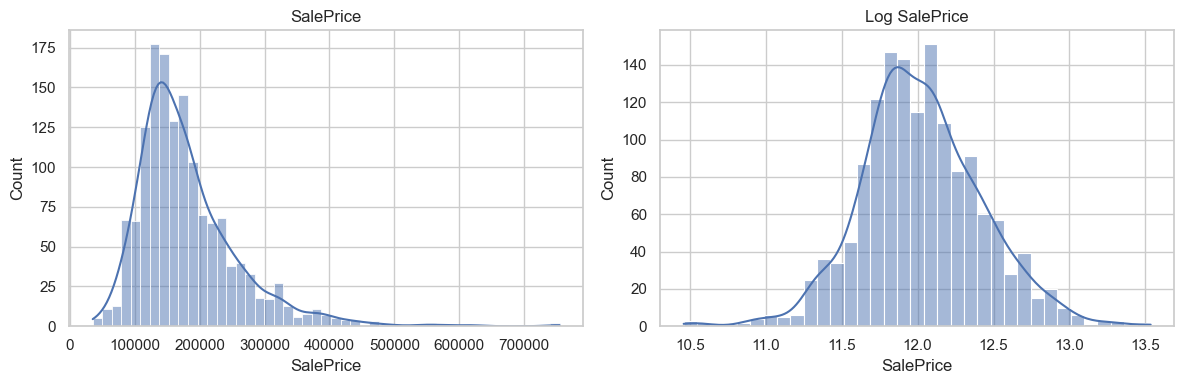

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log(train["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title("Log SalePrice")
plt.tight_layout()
plt.show()


### Missing values

A high missing rate does not always mean that a column is useless. For example, PoolQC can be missing because the house has no pool.


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64


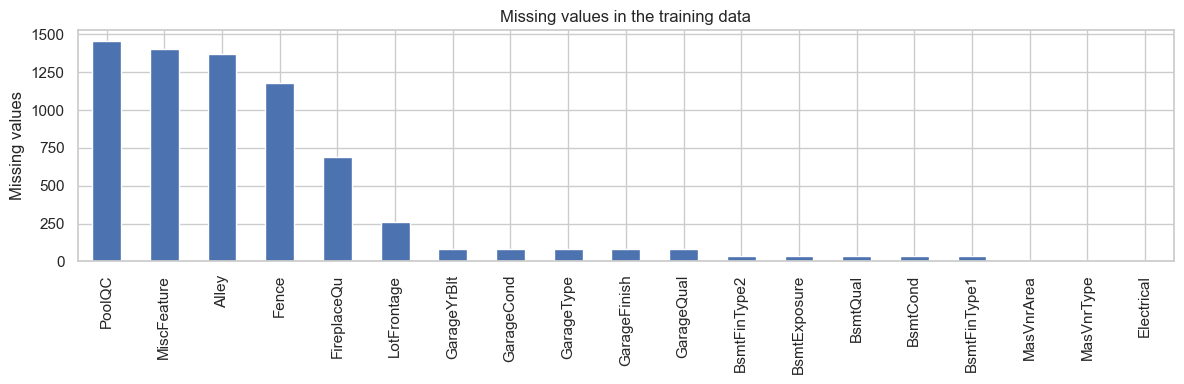

In [49]:
missing = train.isna().sum().sort_values(ascending=False)
print(missing[missing > 0])

missing[missing > 0].plot(kind="bar", figsize=(12, 4))
plt.ylabel("Missing values")
plt.title("Missing values in the training data")
plt.tight_layout()
plt.show()


### Relationships with price

Look at living area, overall quality, and neighborhood. Large houses with low prices are worth checking, but we keep them in this first version.


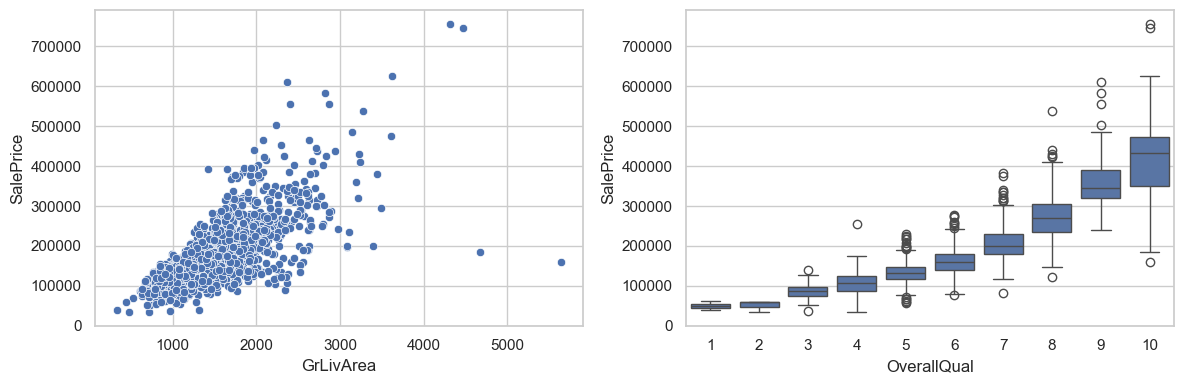

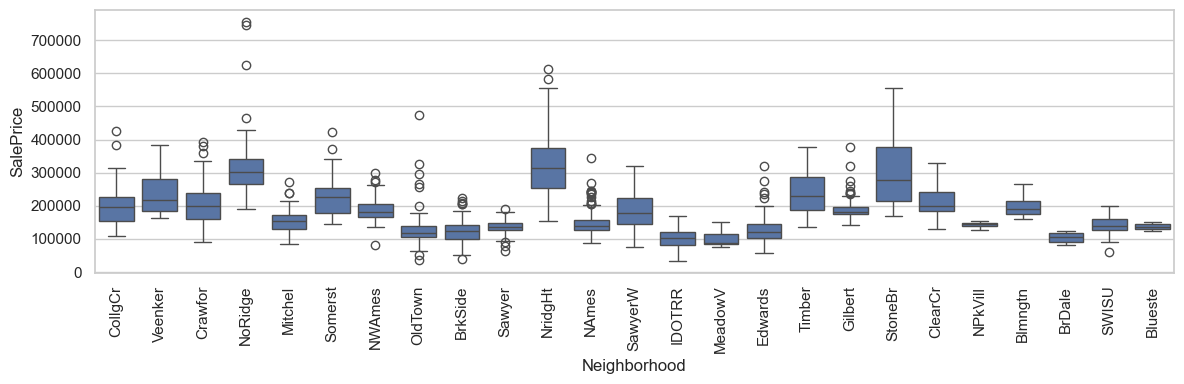

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", ax=axes[0])
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes[1])
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
sns.boxplot(data=train, x="Neighborhood", y="SalePrice")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


### Correlation

Show the full correlation matrix for numeric measurements and SalePrice. Exclude Id and the category codes MSSubClass and MoSold.
A larger figure helps us see relationships between features, including possible redundancy. Correlation does not prove causation.


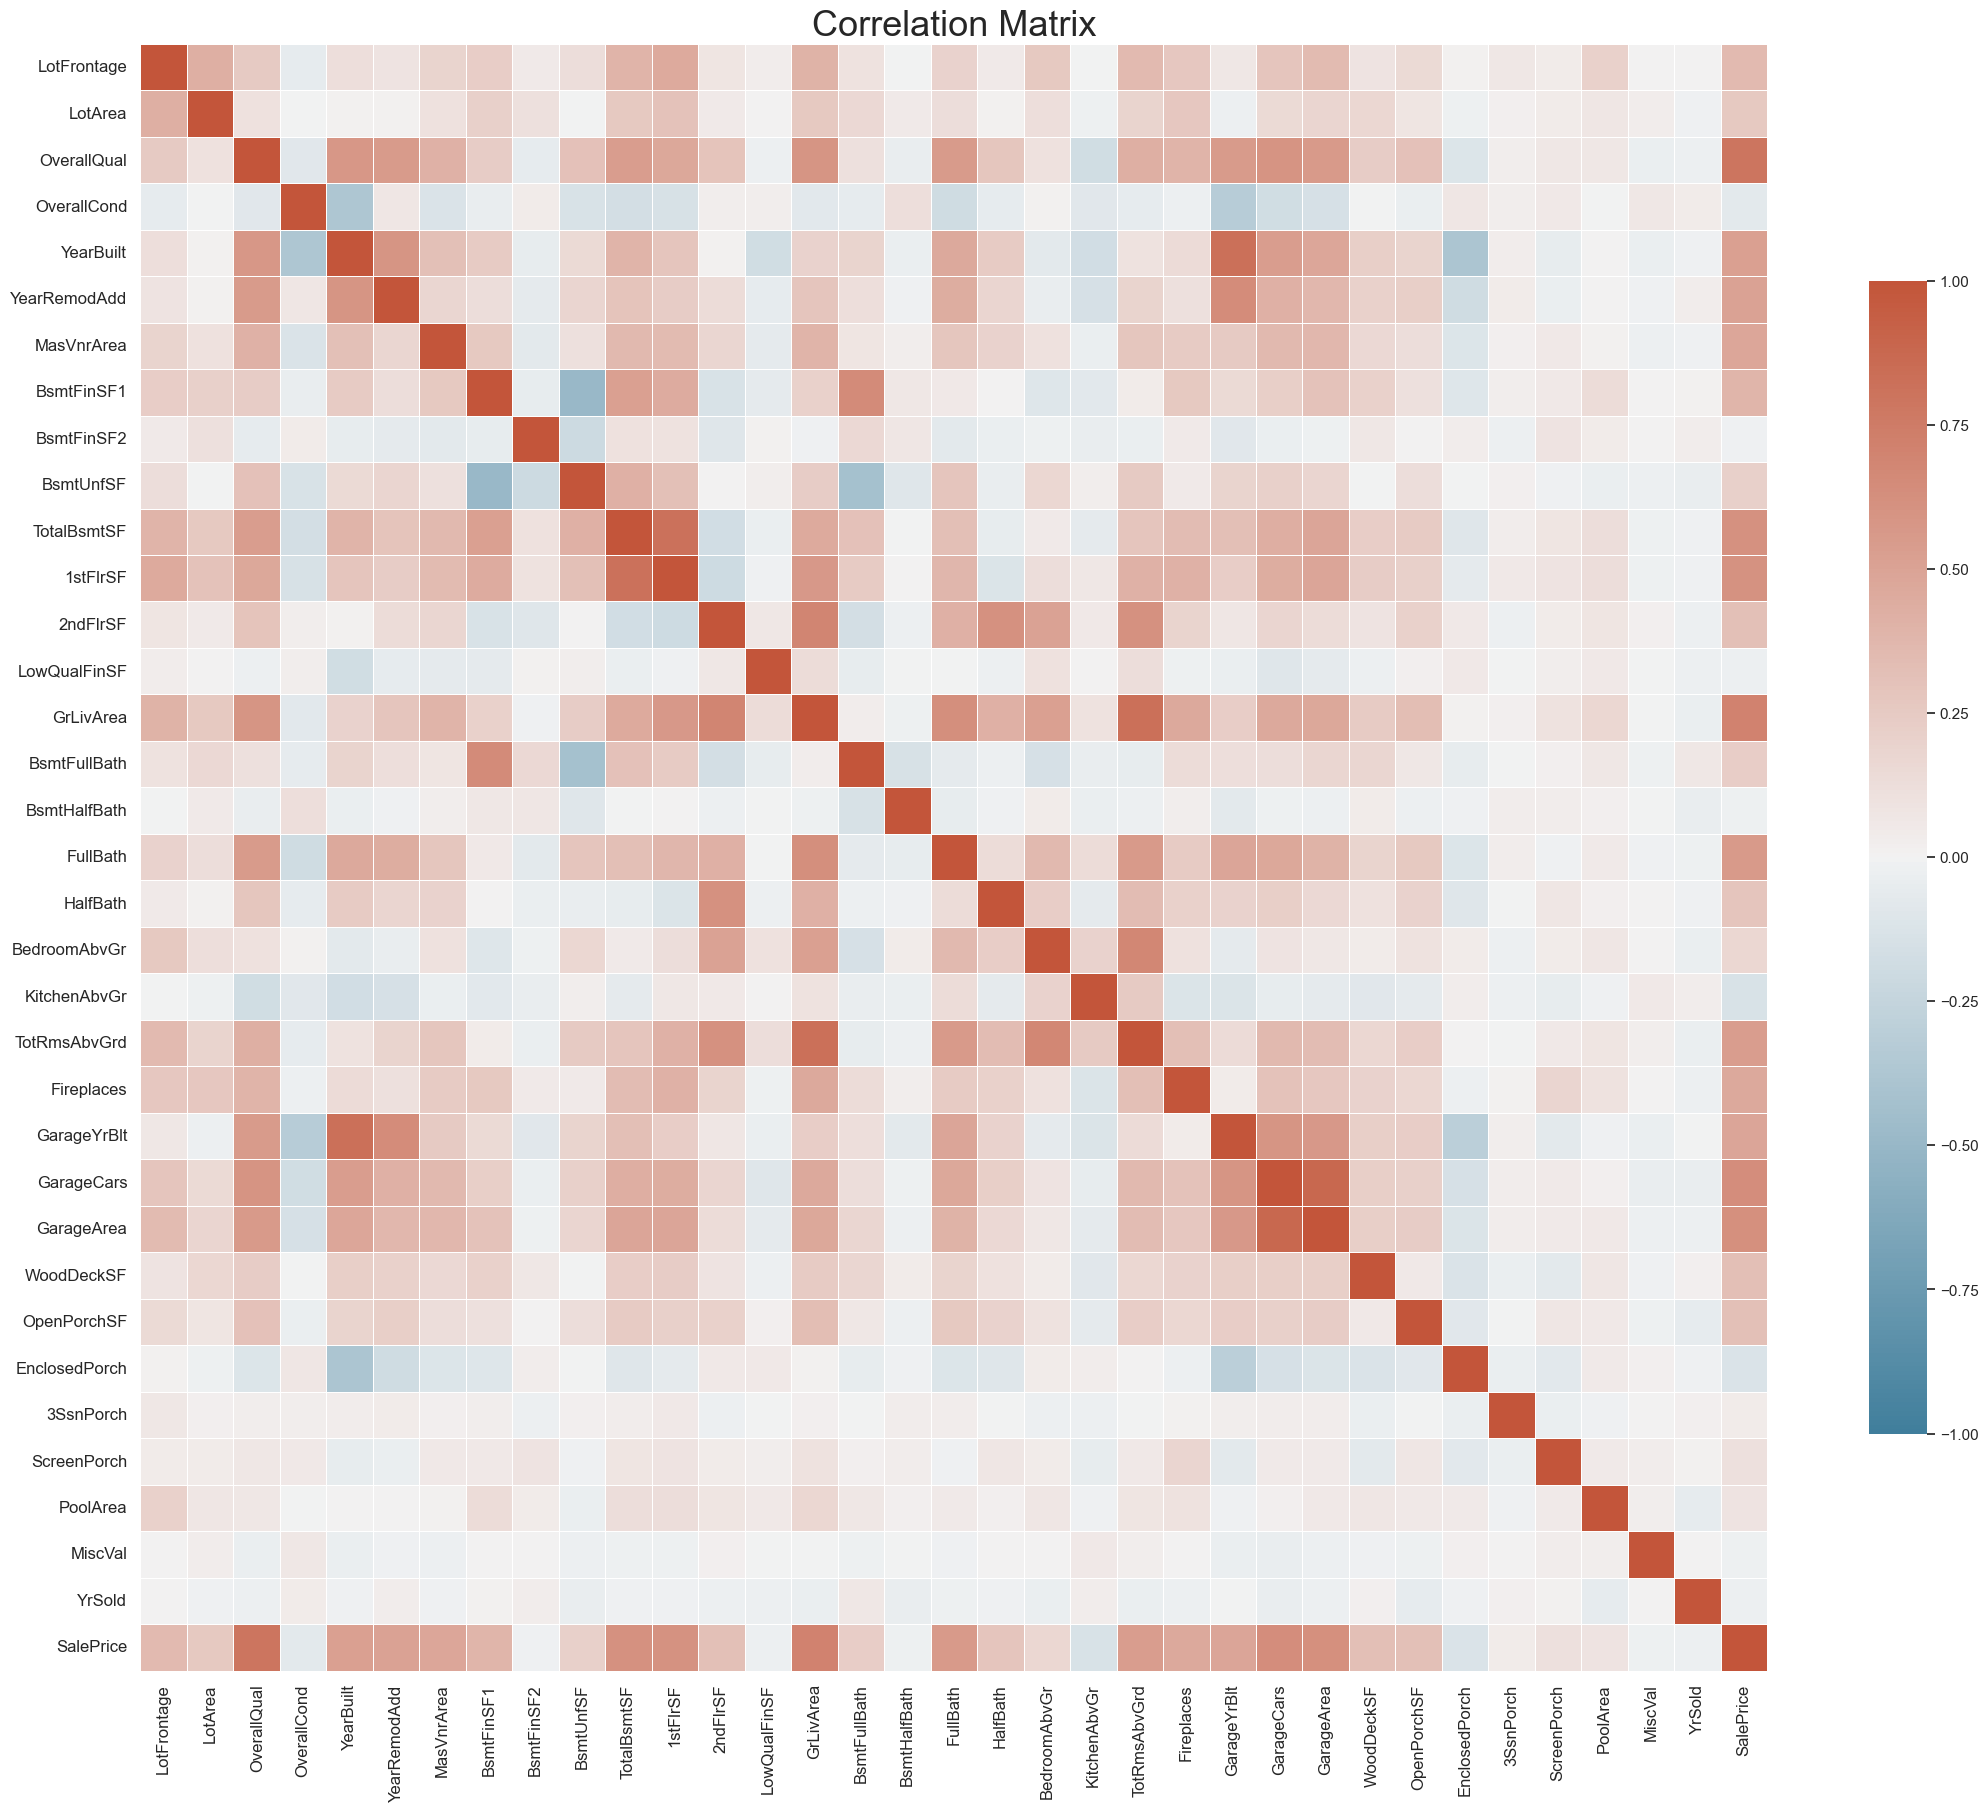

In [51]:
corr = train.drop(columns=["Id", "MSSubClass", "MoSold"]).select_dtypes(include=np.number).corr()

plt.figure(figsize=(22, 20))
sns.heatmap(corr, cmap=sns.diverging_palette(230, 20, as_cmap=True),
            center=0, vmin=-1, vmax=1, square=True, annot=False,
            linewidths=0.5, cbar_kws={"shrink": 0.6})
plt.title("Correlation Matrix", fontsize=26)
plt.xticks(rotation=90, fontsize=12)
plt.yticks(rotation=0, fontsize=12)
plt.tight_layout()
plt.show()


## 4. Clean the data

Id is not a predictor. We join the feature rows to apply the same fixed cleaning rules to train and test.
Medians, modes, encoding categories, and scaling are learned later from the training split only.


In [52]:
y = np.log(train["SalePrice"])
test_ids = test["Id"].copy()

train_features = train.drop(columns=["Id", "SalePrice"])
test_features = test.drop(columns="Id")
data = pd.concat([train_features, test_features], ignore_index=True)


### Missing facilities and invalid years

For structural fields, this version treats missing categories as "None" and missing facility amounts as zero, following the reference's simple approach.
This is an assumption: a few houses may have incomplete facility records and need closer review later.
Missing MasVnrType is kept as "Unknown" to distinguish it from the recorded category "None".

MSSubClass and MoSold are category codes. Years stay numeric to avoid creating many year dummy columns.


In [53]:
none_columns = ["Alley", "Fence", "MiscFeature", "PoolQC", "FireplaceQu",
                "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
for col in none_columns:
    data[col] = data[col].fillna("None")

data["MasVnrType"] = data["MasVnrType"].fillna("Unknown")

zero_columns = ["GarageArea", "GarageCars", "TotalBsmtSF", "BsmtFinSF1",
                "BsmtFinSF2", "BsmtUnfSF", "BsmtFullBath", "BsmtHalfBath"]
for col in zero_columns:
    data[col] = data[col].fillna(0)

for col in ["YearBuilt", "YearRemodAdd", "GarageYrBlt"]:
    invalid_year = (data[col] < 1800) | (data[col] > data["YrSold"] + 1)
    print(col, "invalid years:", invalid_year.sum())
    data.loc[invalid_year, col] = np.nan

data["MSSubClass"] = data["MSSubClass"].astype(str)
data["MoSold"] = data["MoSold"].astype(str)

# Save the original column names for a feature-engineering comparison.
base_columns = data.columns.tolist()


YearBuilt invalid years: 0
YearRemodAdd invalid years: 1
GarageYrBlt invalid years: 1


## 5. Feature engineering

We add only six features:
- TotalSF: basement area + first-floor area + second-floor area.
- TotalBath: full bathrooms + half of the half bathrooms, including the basement.
- HouseAge: years between construction and sale.
- RemodelAge: years since the last remodel.
- HasGarage and HasBasement: whether these facilities exist.

These features may help a linear model capture size, age, and facility effects. They may also repeat information already in the original columns.
We will compare Ridge with and without them instead of assuming more features are better.


In [54]:
data["TotalSF"] = data["TotalBsmtSF"] + data["1stFlrSF"] + data["2ndFlrSF"]
data["TotalBath"] = (data["FullBath"] + 0.5 * data["HalfBath"]
                     + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"])
# Clip small negative ages to zero for houses sold around their construction year.
data["HouseAge"] = (data["YrSold"] - data["YearBuilt"]).clip(lower=0)
data["RemodelAge"] = (data["YrSold"] - data["YearRemodAdd"]).clip(lower=0)
data["HasGarage"] = (data["GarageArea"] > 0).astype(int)
data["HasBasement"] = (data["TotalBsmtSF"] > 0).astype(int)

new_columns = ["TotalSF", "TotalBath", "HouseAge", "RemodelAge", "HasGarage", "HasBasement"]
data[new_columns].head()


,TotalSF,TotalBath,HouseAge,RemodelAge,HasGarage,HasBasement
0,2566.0,3.5,5.0,5.0,1,1
1,2524.0,2.5,31.0,31.0,1,1
2,2706.0,3.5,7.0,6.0,1,1
3,2473.0,2.0,91.0,36.0,1,1
4,3343.0,3.5,8.0,8.0,1,1


### Log-transform area features

Apply log1p to selected non-negative area columns to reduce the effect of very large values. log1p also handles zero.
Area totals are calculated before this transformation. The same transformations are used in both Ridge comparisons.


In [55]:
log_columns = ["LotArea", "GrLivArea", "TotalBsmtSF", "1stFlrSF",
               "2ndFlrSF", "MasVnrArea", "TotalSF"]
for col in log_columns:
    data[col] = np.log1p(data[col])


## 6. Prepare a validation set

Use the same 80/20 split for both feature sets. Fill remaining numeric values with training medians and categorical values with training modes, then apply one-hot encoding.
Unknown validation categories become all-zero dummy values.


In [56]:
X = data.iloc[:len(train)].copy()
X_test = data.iloc[len(train):].copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

medians = X_train.median(numeric_only=True)
modes = X_train.select_dtypes(include="object").mode().iloc[0]
X_train = X_train.fillna(medians).fillna(modes)
X_valid = X_valid.fillna(medians).fillna(modes)

# Identify the baseline columns before encoding adds dummy columns.
X_train_base = pd.get_dummies(X_train[base_columns], dtype=int)
X_valid_base = pd.get_dummies(X_valid[base_columns], dtype=int)
X_valid_base = X_valid_base.reindex(columns=X_train_base.columns, fill_value=0)

X_train = pd.get_dummies(X_train, dtype=int)
X_valid = pd.get_dummies(X_valid, dtype=int)
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Remaining missing values:", X_train.isna().sum().sum(), X_valid.isna().sum().sum())


Training: (1168, 332)
Validation: (292, 332)
Remaining missing values: 0 0


### Scale the features

Scale the features before fitting Ridge so that their units do not determine the strength of the penalty.
Fit each scaler on the training split and apply it to the validation split.


In [57]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

base_scaler = StandardScaler()
X_train_base_scaled = base_scaler.fit_transform(X_train_base)
X_valid_base_scaled = base_scaler.transform(X_valid_base)


## 7. Compare Ridge with and without the new features

Keep the model, split, cleaning, and transformations fixed. Record validation error, fitting time, and feature count.
A lower log-RMSE is better. A small change on one split is not strong evidence; later versions can check it with cross-validation.


In [58]:
ridge_base = Ridge(alpha=10)
start = perf_counter()
ridge_base.fit(X_train_base_scaled, y_train)
base_time = perf_counter() - start
base_pred = ridge_base.predict(X_valid_base_scaled)
base_score = np.sqrt(mean_squared_error(y_valid, base_pred))

ridge = Ridge(alpha=10)
start = perf_counter()
ridge.fit(X_train_scaled, y_train)
ridge_time = perf_counter() - start
ridge_pred = ridge.predict(X_valid_scaled)
ridge_score = np.sqrt(mean_squared_error(y_valid, ridge_pred))

feature_comparison = pd.DataFrame({
    "Features": ["Original", "Original + 6 new features"],
    "Validation log-RMSE": [base_score, ridge_score],
    "Fit seconds": [base_time, ridge_time],
    "Feature count": [X_train_base.shape[1], X_train.shape[1]]
})
feature_comparison


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-p

,Features,Validation log-RMSE,Fit seconds,Feature count
0,Original,0.124284,0.004650,326
1,Original + 6 new features,0.123827,0.002179,332


## 8. Choose the feature set and check prediction errors

Keep the feature set with the lower validation log-RMSE. Both choices use the same Ridge model and alpha=10.
Since this validation set is used for selection, its score is not an independent final test score.


Model: Ridge (alpha=10)
Selected features: Original + 6 new features


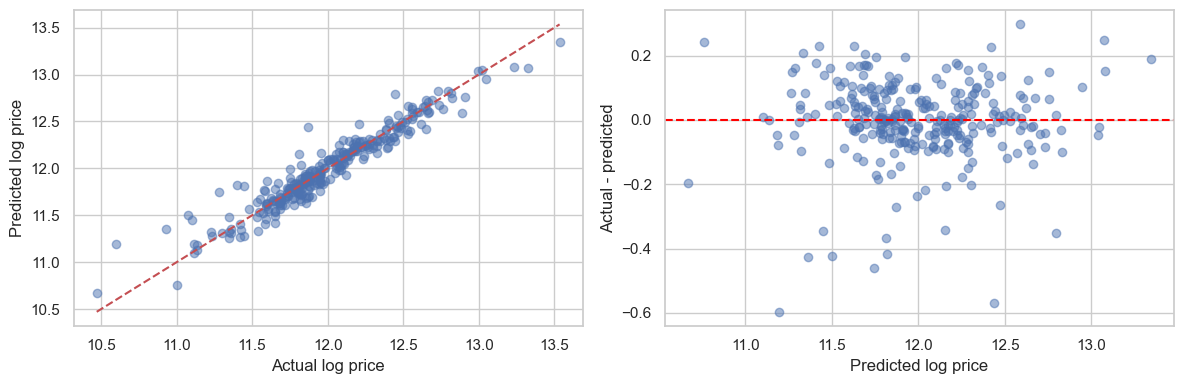

In [59]:
if ridge_score < base_score:
    selected_features = "Original + 6 new features"
    best_valid_pred = ridge_pred
else:
    selected_features = "Original"
    best_valid_pred = base_pred

print("Model: Ridge (alpha=10)")
print("Selected features:", selected_features)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_valid, best_valid_pred, alpha=0.5)
axes[0].plot([y_valid.min(), y_valid.max()], [y_valid.min(), y_valid.max()], "r--")
axes[0].set(xlabel="Actual log price", ylabel="Predicted log price")
axes[1].scatter(best_valid_pred, y_valid - best_valid_pred, alpha=0.5)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Predicted log price", ylabel="Actual - predicted")
plt.tight_layout()
plt.show()


## 9. Train Ridge on all training rows and predict test prices

Use the selected feature set. Recalculate medians, modes, dummy columns, and scaling using all training rows, then refit Ridge.
The test data never supplies these statistics.


In [60]:
medians = X.median(numeric_only=True)
modes = X.select_dtypes(include="object").mode().iloc[0]
X_full = X.fillna(medians).fillna(modes)
X_test_full = X_test.fillna(medians).fillna(modes)

if selected_features == "Original":
    X_full = X_full[base_columns]
    X_test_full = X_test_full[base_columns]

X_full = pd.get_dummies(X_full, dtype=int)
X_test_full = pd.get_dummies(X_test_full, dtype=int)
X_test_full = X_test_full.reindex(columns=X_full.columns, fill_value=0)

scaler = StandardScaler()
X_full_scaled = scaler.fit_transform(X_full)
X_test_scaled = scaler.transform(X_test_full)

final_ridge = Ridge(alpha=10)
final_ridge.fit(X_full_scaled, y)
test_pred_log = final_ridge.predict(X_test_scaled)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-p

## 10. Save the submission

In [64]:
submission = pd.DataFrame({"Id": test_ids, "SalePrice": np.exp(test_pred_log)})
assert len(submission) == len(test)
assert np.isfinite(submission["SalePrice"]).all()
assert (submission["SalePrice"] > 0).all()

submission.to_csv("submission_v1.csv", index=False)


print("Model: Ridge (alpha=10)")
print("Selected features:", selected_features)
print(f"Validation log-RMSE: {min(base_score, ridge_score):.6f}")
print("Final training rows:", len(train))
print("Predicted test rows:", len(submission))
print("Submission file saved！")
submission.head()


Model: Ridge (alpha=10)
Selected features: Original + 6 new features
Validation log-RMSE: 0.123827
Final training rows: 1460
Predicted test rows: 1459
Submission file saved！


,Id,SalePrice
0,1461,120785.195184
1,1462,174191.861771
2,1463,185991.383715
3,1464,204877.290857
4,1465,196631.134079
